In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

In [ ]:
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import r2_score, mean_squared_error
from sklearn.pipeline import Pipeline

In [ ]:
df = pd.read_csv("3-customersatisfaction.csv")

In [ ]:
df.head(5)

,Unnamed: 0,Customer Satisfaction,Incentive
0,0,-1.282447,1.010513
1,1,0.425298,2.281043
2,2,1.953070,4.415053
3,3,2.625838,10.563600
4,4,-1.426333,0.627365


In [ ]:
df.drop("Unnamed: 0", axis = 1, inplace=True)

In [ ]:
df.head(5)

,Customer Satisfaction,Incentive
0,-1.282447,1.010513
1,0.425298,2.281043
2,1.953070,4.415053
3,2.625838,10.563600
4,-1.426333,0.627365


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100 entries, 0 to 99
Data columns (total 2 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   Customer Satisfaction  100 non-null    float64
 1   Incentive              100 non-null    float64
dtypes: float64(2)
memory usage: 1.7 KB


In [ ]:
df.describe()

,Customer Satisfaction,Incentive
count,100.000000,100.000000
mean,-0.005427,3.445220
std,1.721792,2.911818
min,-2.992863,-1.068081
25%,-1.431357,1.471341
50%,0.109167,2.748839
75%,1.421119,4.739113
max,2.986736,11.000056


In [ ]:
df.isnull().sum()

,0
Customer Satisfaction,0
Incentive,0


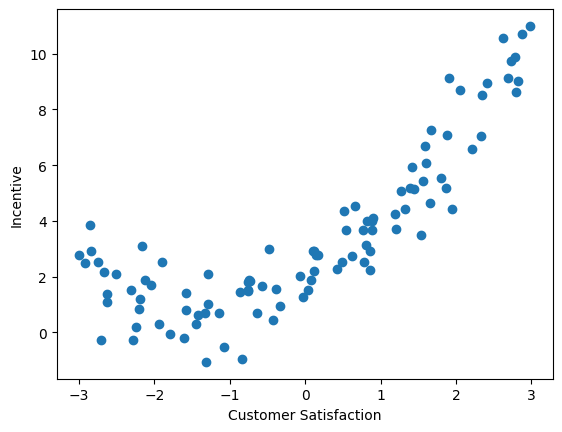

In [ ]:
plt.scatter(df["Customer Satisfaction"], df["Incentive"])
plt.xlabel("Customer Satisfaction")
plt.ylabel("Incentive")
plt.show()

In [ ]:
X = df[["Customer Satisfaction"]]
y = df["Incentive"]

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=15)

In [ ]:
regression = LinearRegression()

In [ ]:
scaler = StandardScaler()

In [ ]:
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

In [ ]:
regression.fit(X_train,y_train)

LinearRegression()

In [ ]:
y_pred = regression.predict(X_test)

In [ ]:
y_pred

array([ 4.65663741,  3.71913877,  1.64121789,  6.29646523,  3.46766736,
        5.7580845 ,  4.692485  ,  3.61616231,  5.62448003,  0.13472702,
        4.47909659,  4.8130839 ,  1.58319087,  0.30515983,  5.27634309,
        0.41711005, -0.7385295 , -0.32653914,  3.55906887,  1.19798631])

In [ ]:
score = r2_score(y_test, y_pred)
score

0.2705652535622246

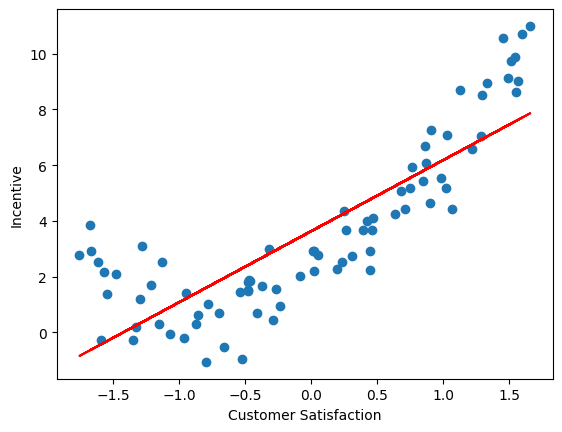

In [ ]:
plt.scatter(X_train, y_train)
plt.plot(X_train, regression.predict(X_train), color = "r")
plt.xlabel("Customer Satisfaction")
plt.ylabel("Incentive")
plt.show()

In [ ]:
#When using a linear regression model, it doesn't give us a proper output.
#Linear regression is insufficient.

In [ ]:
poly = PolynomialFeatures(degree=2)

In [ ]:
X_train_poly = poly.fit_transform(X_train)
X_test_poly = poly.transform(X_test)

In [ ]:
regression = LinearRegression()
regression.fit(X_train_poly, y_train)

LinearRegression()

In [ ]:
y_pred = regression.predict(X_test_poly)

In [ ]:
score = r2_score(y_test, y_pred)
score

0.7685687698788557

In [ ]:
regression.coef_

array([0.        , 2.63871762, 1.54959954])

In [ ]:
regression.intercept_

np.float64(2.076676429793281)

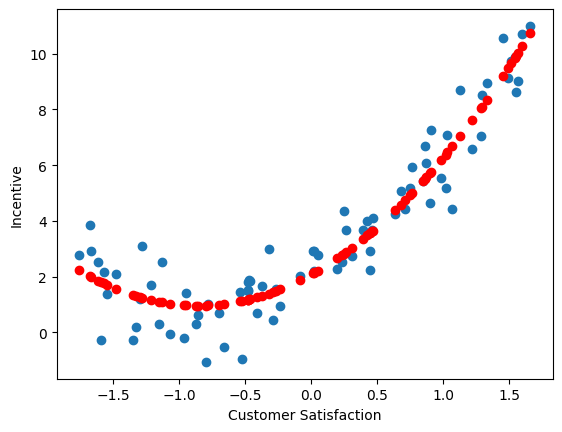

In [ ]:
plt.scatter(X_train, y_train)
plt.scatter(X_train, regression.predict(X_train_poly), color = "r")
plt.xlabel("Customer Satisfaction")
plt.ylabel("Incentive")
plt.show()

In [ ]:
poly = PolynomialFeatures(degree=3)
X_train_poly = poly.fit_transform(X_train)
X_test_poly = poly.transform(X_test)

In [ ]:
regression = LinearRegression()
regression.fit(X_train_poly, y_train)
y_pred = regression.predict(X_test_poly)
score = r2_score(y_test, y_pred)
print(score)

0.757344362140105


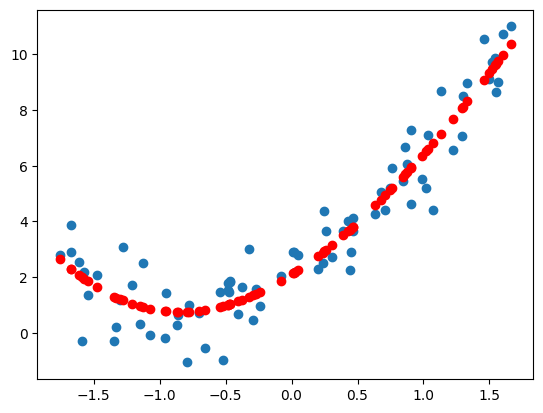

In [ ]:
plt.scatter(X_train, y_train)
plt.scatter(X_train, regression.predict(X_train_poly), color = "r")
plt.show()

In [ ]:
#As the degree increased, the r2 score decreased.

In [ ]:
#new data

In [ ]:
new_df = pd.read_csv("3-newdatas.csv")

In [ ]:
new_df.head(5)

,0
0,-3.000000
1,-2.969849
2,-2.939698
3,-2.909548
4,-2.879397


In [ ]:
new_df.rename(columns = {"0": "Customer Satisfaction"}, inplace=True)

In [ ]:
new_df.head(5)

,Customer Satisfaction
0,-3.000000
1,-2.969849
2,-2.939698
3,-2.909548
4,-2.879397


In [ ]:
X_new = new_df[["Customer Satisfaction"]]
X_new

,Customer Satisfaction
0,-3.000000
1,-2.969849
2,-2.939698
3,-2.909548
4,-2.879397
...,...
195,2.879397
196,2.909548
197,2.939698
198,2.969849


In [ ]:
X_new = scaler.transform(X_new)

In [ ]:
X_new_poly = poly.transform(X_new)

In [ ]:
y_new = regression.predict(X_new_poly)

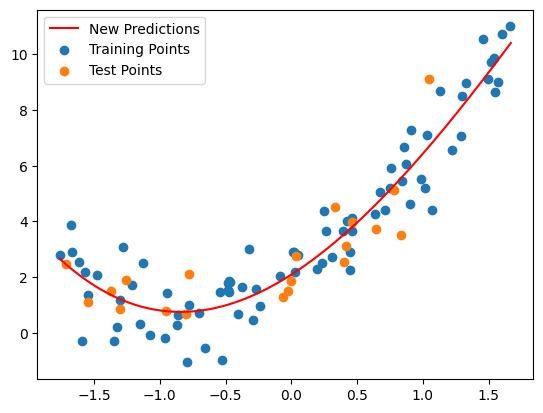

In [ ]:
plt.plot(X_new, y_new, "r", label="New Predictions")
plt.scatter(X_train, y_train, label="Training Points")
plt.scatter(X_test, y_test, label="Test Points")
plt.legend()
plt.show()